In [1]:
from gseapy import dotplot, barplot
import gseapy as gp
import seaborn as sns
import matplotlib.pyplot as plt

import pandas as pd
gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv').set_index('gene')

all_enriched_terms = []
all_gsea_results = []

for col in gene_level_local_metrics.columns.tolist():
    
    tmp = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{col}.csv')
    tmp = tmp[tmp["FDR q-val"]<0.001].sort_values("NES")[::-1]
    all_gsea_results.append(tmp)
    #sns.barplot(tmp, y="Term", x="NES", color="black", orient="y")
    #plt.grid(False)
    all_enriched_terms += tmp['Term'].tolist()

all_enriched_terms = list(set(all_enriched_terms))

print(len(all_enriched_terms))

301


In [2]:
plot_gsea_data = []
geneset_metadata = []
for terms in all_enriched_terms:
    geneset_metadata.append(terms.split('__')[0])
    tmp = []
    for col_id in range(len(gene_level_local_metrics.columns.tolist())):
        gsea_res = all_gsea_results[col_id]
        fdr = gsea_res[gsea_res['Term']==terms]['FDR q-val'].values
        if len(fdr)==0:
            fdr = 1
        else:
            if len(fdr)>1:
                AssertionError
            fdr = fdr[0]
        tmp.append(fdr)
    plot_gsea_data.append(tmp)

In [3]:
import numpy as np
plot_df = pd.DataFrame(data = np.concatenate([np.array(plot_gsea_data), np.array(geneset_metadata)[:, None]], axis=1))
go_res = np.array(plot_df[plot_df[28]=='GO_Biological_Process_2023'].T.iloc[:-1].T.values, dtype=np.float32)
gwas_res = np.array(plot_df[plot_df[28]=='GWAS_Catalog_2025'].T.iloc[:-1].T.values, dtype=np.float32)
corum_res = np.array(plot_df[plot_df[28]=='CORUM'].T.iloc[:-1].T.values, dtype=np.float32)

<Figure size 1200x1600 with 0 Axes>

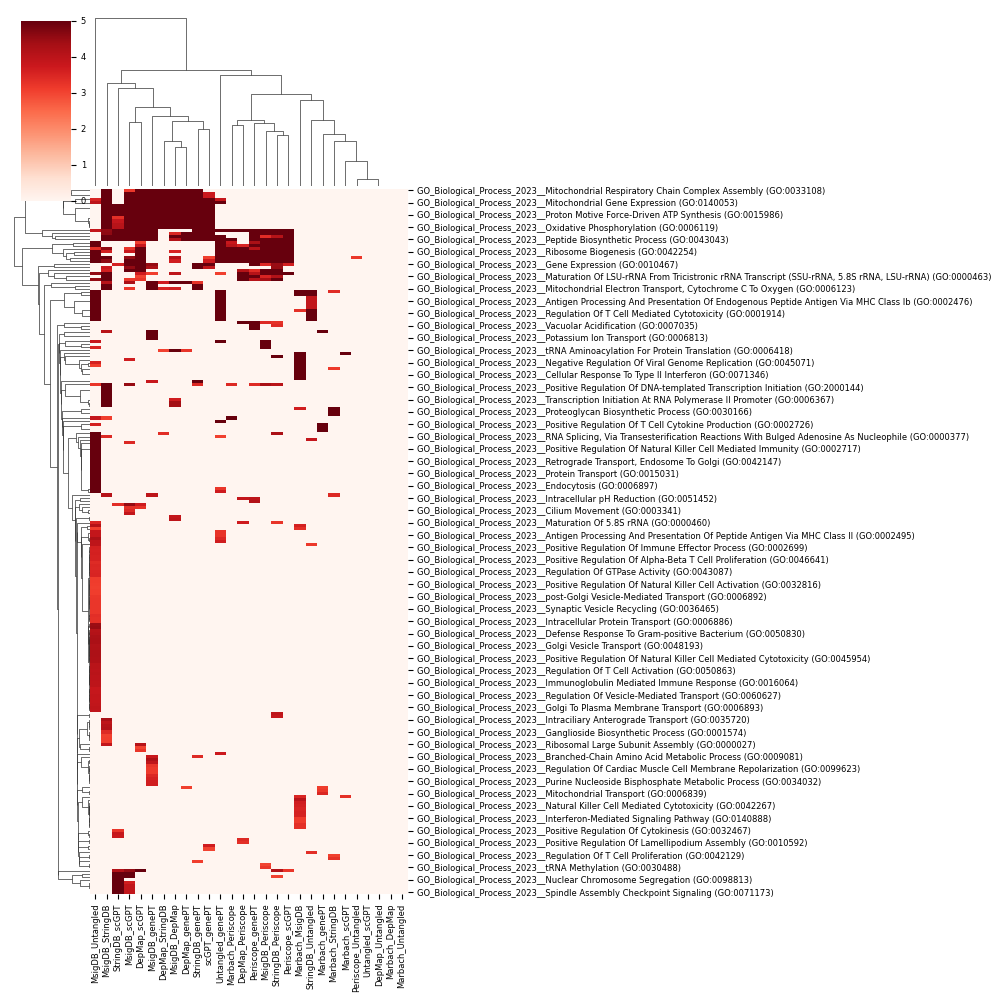

In [4]:
plt.rc('font', size=6)
plt.figure(figsize=(12,16))
clustermap_df = pd.DataFrame(-np.log10(go_res+1e-10), index=np.array(all_enriched_terms)[plot_df[28]=='GO_Biological_Process_2023'].tolist(), columns=gene_level_local_metrics.columns.tolist())
#clustermap_df = clustermap_df.drop('MsigDB_StringDB', axis=1)
clustermap_df = clustermap_df.drop(clustermap_df[clustermap_df.T.sum(axis=0)==0].index.tolist(), axis=0)
cluster_result = sns.clustermap(clustermap_df, col_cluster=True, vmin=0, vmax=5, cmap='Reds')
gobp_col_indices = cluster_result.dendrogram_col.reordered_ind
gobp_row_indices = cluster_result.dendrogram_row.reordered_ind
save_df_gobp = clustermap_df.iloc[gobp_row_indices, gobp_col_indices]

<Figure size 600x400 with 0 Axes>

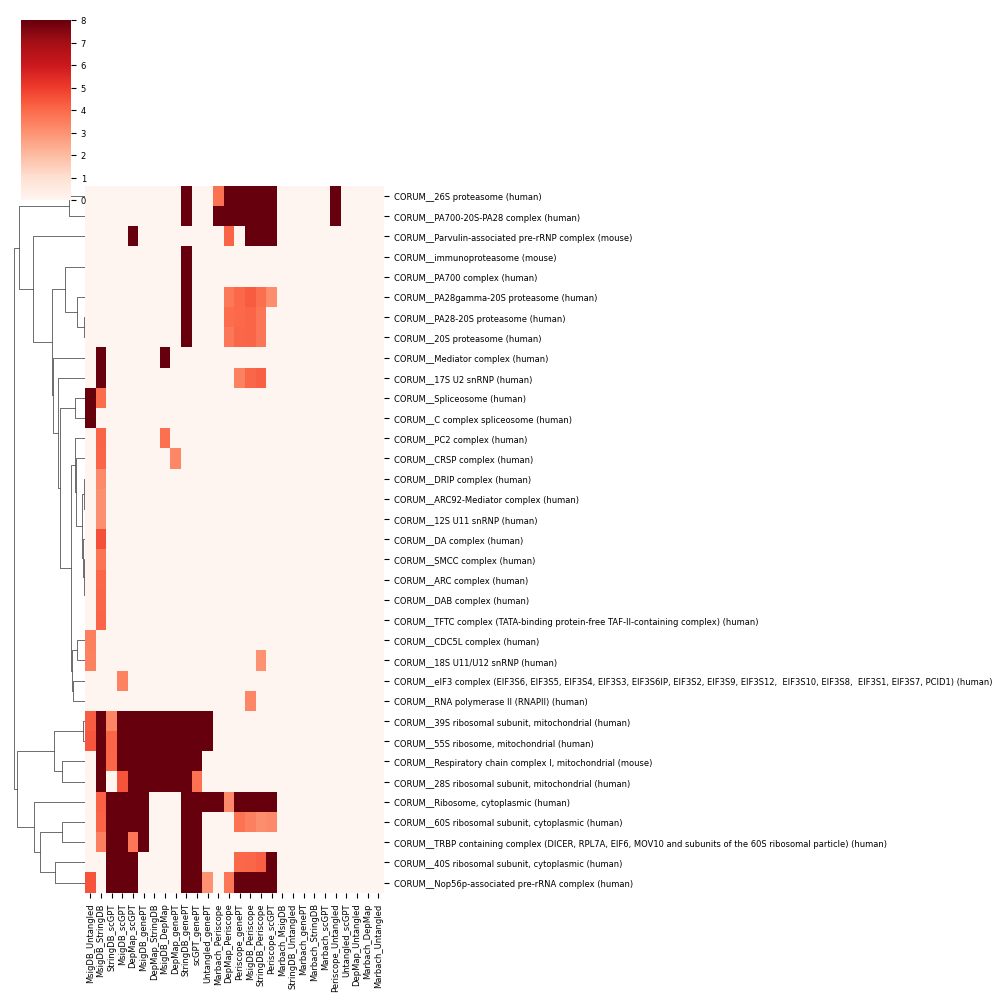

In [5]:
plt.rc('font', size=6)
plt.figure(figsize=(6, 4))

col_indices = cluster_result.dendrogram_col.reordered_ind
clustermap_df = pd.DataFrame(-np.log10(corum_res+1e-10), index=np.array(all_enriched_terms)[plot_df[28]=='CORUM'].tolist(), columns=gene_level_local_metrics.columns.tolist())
#clustermap_df = clustermap_df.drop('MsigDB_StringDB', axis=1)
clustermap_df = clustermap_df.drop(clustermap_df[clustermap_df.T.sum(axis=0)==0].index.tolist(), axis=0)
reordered_cols = np.array(clustermap_df.columns.tolist())[col_indices]
clustermap_df = clustermap_df[reordered_cols]
corum_result = sns.clustermap(clustermap_df, col_cluster=False, vmin=0, vmax=8, cmap='Reds')
corum_row_indices = corum_result.dendrogram_row.reordered_ind
save_df_corum = clustermap_df.iloc[corum_row_indices]

<Figure size 600x400 with 0 Axes>

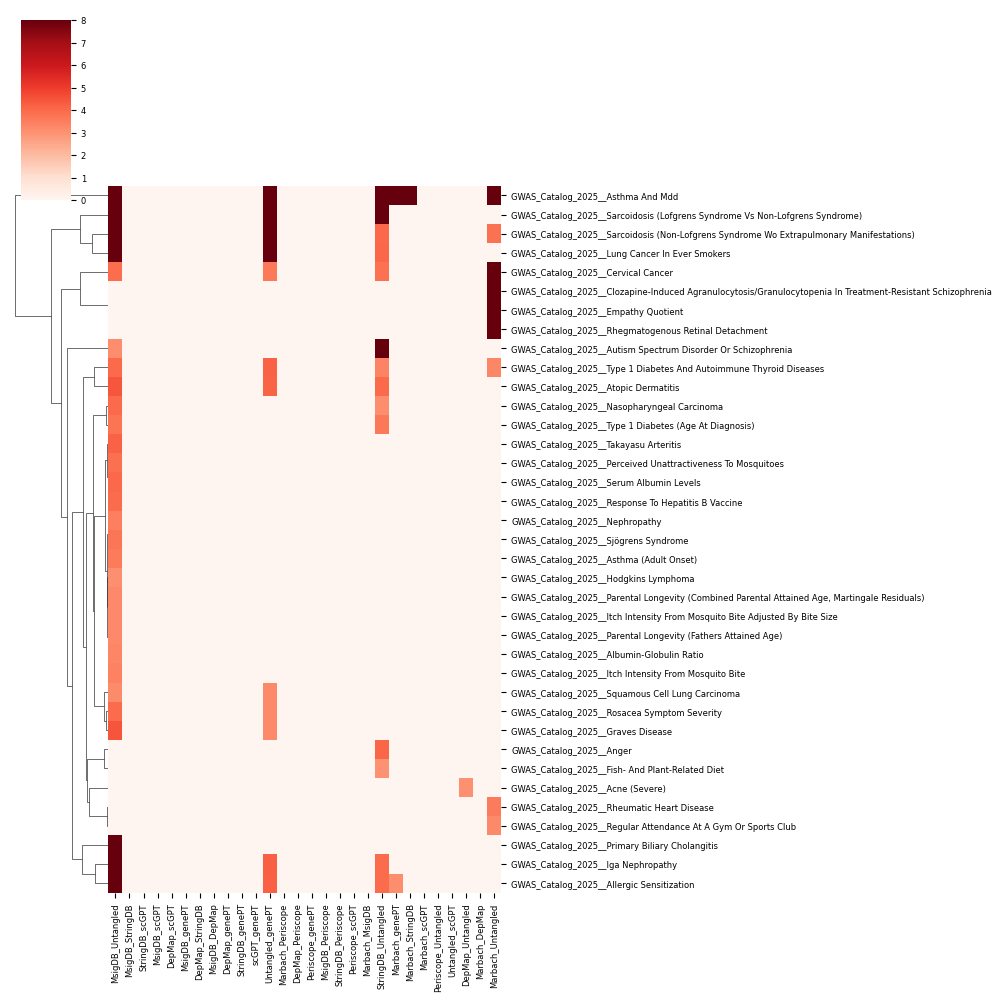

In [6]:
plt.rc('font', size=6)
plt.figure(figsize=(6, 4))

col_indices = cluster_result.dendrogram_col.reordered_ind
clustermap_df = pd.DataFrame(-np.log10(gwas_res+1e-10), index=np.array(all_enriched_terms)[plot_df[28]=='GWAS_Catalog_2025'].tolist(), columns=gene_level_local_metrics.columns.tolist())
clustermap_df = clustermap_df.drop(clustermap_df[clustermap_df.T.sum(axis=0)==0].index.tolist(), axis=0)
reordered_cols = np.array(clustermap_df.columns.tolist())[col_indices]
clustermap_df = clustermap_df[reordered_cols]
gwas_result = sns.clustermap(clustermap_df, col_cluster=False, vmin=0, vmax=8, cmap='Reds')
gwas_row_indices = gwas_result.dendrogram_row.reordered_ind
save_df_gwas = clustermap_df.iloc[gwas_row_indices]

In [ ]:
pd.concat([save_df_gobp, save_df_corum, save_df_gwas], axis=0).to_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/prior_gsea_aggregated.csv')

### GSEA annotation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/prior_gsea_aggregated.csv", index_col=0)
df = df.clip(lower=0)

clusters = {

    
    "C1": {
        "color": "#C0392B",
        "terms": [
            "GO_Biological_Process_2023__Cytoplasmic Translation (GO:0002181)",
            "GO_Biological_Process_2023__Translation (GO:0006412)",
            "GO_Biological_Process_2023__Peptide Biosynthetic Process (GO:0043043)",
            "GO_Biological_Process_2023__Macromolecule Biosynthetic Process (GO:0009059)",
            "GO_Biological_Process_2023__Gene Expression (GO:0010467)",
            "GO_Biological_Process_2023__Cytoplasmic Translational Initiation (GO:0002183)",
            "GO_Biological_Process_2023__Formation Of Cytoplasmic Translation Initiation Complex (GO:0001732)",
            "GO_Biological_Process_2023__Negative Regulation Of Translation (GO:0017148)",
            "GO_Biological_Process_2023__Ribosome Assembly (GO:0042255)",
            "GO_Biological_Process_2023__Ribosomal Small Subunit Assembly (GO:0000028)",
            "GO_Biological_Process_2023__Ribosomal Large Subunit Assembly (GO:0000027)",
            "GO_Biological_Process_2023__tRNA Aminoacylation For Protein Translation (GO:0006418)",
            "GO_Biological_Process_2023__tRNA Aminoacylation (GO:0043039)",      
            "GO_Biological_Process_2023__Ribosome Biogenesis (GO:0042254)",
            "GO_Biological_Process_2023__rRNA Processing (GO:0006364)",
            "GO_Biological_Process_2023__rRNA Metabolic Process (GO:0016072)",
            "GO_Biological_Process_2023__ncRNA Processing (GO:0034470)",
            "GO_Biological_Process_2023__Ribonucleoprotein Complex Biogenesis (GO:0022613)",
            "GO_Biological_Process_2023__protein-RNA Complex Assembly (GO:0022618)",
            "GO_Biological_Process_2023__Ribosomal Small Subunit Biogenesis (GO:0042274)",
            "GO_Biological_Process_2023__Ribosomal Large Subunit Biogenesis (GO:0042273)",
            "GO_Biological_Process_2023__Maturation Of SSU-rRNA (GO:0030490)",
            "GO_Biological_Process_2023__Maturation Of SSU-rRNA From Tricistronic rRNA Transcript (SSU-rRNA, 5.8S rRNA, LSU-rRNA) (GO:0000462)",
            "GO_Biological_Process_2023__Maturation Of LSU-rRNA (GO:0000470)",
            "GO_Biological_Process_2023__Maturation Of LSU-rRNA From Tricistronic rRNA Transcript (SSU-rRNA, 5.8S rRNA, LSU-rRNA) (GO:0000463)",
            "GO_Biological_Process_2023__Maturation Of 5.8S rRNA (GO:0000460)",
            "GO_Biological_Process_2023__Maturation Of 5.8S rRNA From Tricistronic rRNA Transcript (SSU-rRNA, 5.8S rRNA, LSU-rRNA) (GO:0000466)",
            "GO_Biological_Process_2023__Endonucleolytic Cleavage Of Tricistronic rRNA Transcript (SSU-rRNA, 5.8S rRNA, LSU-rRNA) (GO:0000479)",
            "CORUM__Ribosome, cytoplasmic (human)",
            "CORUM__60S ribosomal subunit, cytoplasmic (human)",
            "CORUM__40S ribosomal subunit, cytoplasmic (human)",
            "CORUM__TRBP containing complex (DICER, RPL7A, EIF6, MOV10 and subunits of the 60S ribosomal particle) (human)",
            "CORUM__eIF3 complex (EIF3S6, EIF3S5, EIF3S4, EIF3S3, EIF3S6IP, EIF3S2, EIF3S9, EIF3S12,  EIF3S10, EIF3S8,  EIF3S1, EIF3S7, PCID1) (human)",
            "CORUM__Nop56p-associated pre-rRNA complex (human)",
            "CORUM__Parvulin-associated pre-rRNP complex (mouse)",
        ],
    },

    "C2": {
        "color": "#E67E22",
        "terms": [
            "GO_Biological_Process_2023__Mitochondrial Respiratory Chain Complex Assembly (GO:0033108)",
            "GO_Biological_Process_2023__Mitochondrial Respiratory Chain Complex I Assembly (GO:0032981)",
            "GO_Biological_Process_2023__NADH Dehydrogenase Complex Assembly (GO:0010257)",
            "GO_Biological_Process_2023__Mitochondrial Electron Transport, NADH To Ubiquinone (GO:0006120)",
            "GO_Biological_Process_2023__Mitochondrial Electron Transport, Cytochrome C To Oxygen (GO:0006123)",
            "GO_Biological_Process_2023__Aerobic Electron Transport Chain (GO:0019646)",
            "GO_Biological_Process_2023__Aerobic Respiration (GO:0009060)",
            "GO_Biological_Process_2023__Cellular Respiration (GO:0045333)",
            "GO_Biological_Process_2023__Oxidative Phosphorylation (GO:0006119)",
            "GO_Biological_Process_2023__Proton Motive Force-Driven ATP Synthesis (GO:0015986)",
            "GO_Biological_Process_2023__Proton Motive Force-Driven Mitochondrial ATP Synthesis (GO:0042776)",
            "GO_Biological_Process_2023__Mitochondrial ATP Synthesis Coupled Electron Transport (GO:0042775)",
            "GO_Biological_Process_2023__Energy Derivation By Oxidation Of Organic Compounds (GO:0015980)",
            "GO_Biological_Process_2023__Mitochondrial Translation (GO:0032543)",
            "GO_Biological_Process_2023__Mitochondrial Gene Expression (GO:0140053)",
            "GO_Biological_Process_2023__Regulation Of Mitochondrial Translation (GO:0070129)",
            "GO_Biological_Process_2023__Mitochondrial Transport (GO:0006839)",
            "GO_Biological_Process_2023__Respiratory Chain Complex IV Assembly (GO:0008535)",
            "CORUM__Respiratory chain complex I, mitochondrial (mouse)",
            "CORUM__39S ribosomal subunit, mitochondrial (human)",
            "CORUM__55S ribosome, mitochondrial (human)",
            "CORUM__28S ribosomal subunit, mitochondrial (human)",
        ],
    },

    "C3": {
        "color": "#8E44AD",
        "terms": [
            "GO_Biological_Process_2023__Negative Regulation Of Proteolysis Involved In Protein Catabolic Process (GO:1903051)",
            "GO_Biological_Process_2023__Negative Regulation Of Ubiquitin-Protein Transferase Activity (GO:0051444)",
            "GO_Biological_Process_2023__Positive Regulation Of Signal Transduction By P53 Class Mediator (GO:1901798)",
            "CORUM__PA700-20S-PA28 complex (human)",
            "CORUM__26S proteasome (human)",
            "CORUM__PA28gamma-20S proteasome (human)",
            "CORUM__20S proteasome (human)",
            "CORUM__PA28-20S proteasome (human)",
            "CORUM__PA700 complex (human)",
            "CORUM__immunoproteasome (mouse)",
        ],
    },

    "C4": {
        "color": "#27AE60",
        "terms": [
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Endogenous Peptide Antigen (GO:0002483)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Endogenous Peptide Antigen Via MHC Class Ib (GO:0002476)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Endogenous Peptide Antigen Via MHC Class I Via ER Pathway (GO:0002484)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Endogenous Peptide Antigen Via MHC Class I Via ER Pathway, TAP-independent (GO:0002486)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Peptide Antigen Via MHC Class Ib (GO:0002428)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Peptide Antigen Via MHC Class I (GO:0002474)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Exogenous Peptide Antigen (GO:0002478)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Exogenous Peptide Antigen Via MHC Class II (GO:0019886)",
            "GO_Biological_Process_2023__Antigen Processing And Presentation Of Peptide Antigen Via MHC Class II (GO:0002495)",
            "GO_Biological_Process_2023__Antigen Receptor-Mediated Signaling Pathway (GO:0050851)",
            "GO_Biological_Process_2023__T Cell Receptor Signaling Pathway (GO:0050852)",
            "GO_Biological_Process_2023__T Cell Mediated Immunity (GO:0002456)",
            "GO_Biological_Process_2023__Positive Regulation Of Leukocyte Mediated Cytotoxicity (GO:0001912)",
            "GO_Biological_Process_2023__Positive Regulation Of T Cell Mediated Cytotoxicity (GO:0001916)",
            "GO_Biological_Process_2023__Regulation Of T Cell Mediated Cytotoxicity (GO:0001914)",
            "GO_Biological_Process_2023__Positive Regulation Of T Cell Mediated Immunity (GO:0002711)",
            "GO_Biological_Process_2023__Immunoglobulin Mediated Immune Response (GO:0016064)",
        ],
    },

    "C5": {
        "color": "#2980B9",
        "terms": [
            "GO_Biological_Process_2023__U2-type Prespliceosome Assembly (GO:1903241)",
            "GO_Biological_Process_2023__Spliceosomal snRNP Assembly (GO:0000387)",
            "GO_Biological_Process_2023__Spliceosomal Complex Assembly (GO:0000245)",
            "GO_Biological_Process_2023__mRNA Splicing, Via Spliceosome (GO:0000398)",
            "GO_Biological_Process_2023__RNA Splicing, Via Transesterification Reactions With Bulged Adenosine As Nucleophile (GO:0000377)",
            "GO_Biological_Process_2023__RNA Splicing (GO:0008380)",
            "GO_Biological_Process_2023__Regulation Of mRNA Splicing, Via Spliceosome (GO:0048024)",
            "GO_Biological_Process_2023__Regulation Of RNA Splicing (GO:0043484)",
            "GO_Biological_Process_2023__mRNA Processing (GO:0006397)",
            "GO_Biological_Process_2023__RNA Processing (GO:0006396)",
            "GO_Biological_Process_2023__Nuclear RNA Surveillance (GO:0071027)",
            "GO_Biological_Process_2023__RNA Methylation (GO:0001510)",
            "GO_Biological_Process_2023__tRNA Modification (GO:0006400)",
            "GO_Biological_Process_2023__tRNA Processing (GO:0008033)",
            "GO_Biological_Process_2023__tRNA Methylation (GO:0030488)",
            "GO_Biological_Process_2023__Monoubiquitinated Histone H2A Deubiquitination (GO:0035522)",
            "GO_Biological_Process_2023__Monoubiquitinated Histone Deubiquitination (GO:0035521)",
            "CORUM__Spliceosome (human)",
            "CORUM__C complex spliceosome (human)",
            "CORUM__17S U2 snRNP (human)",
            "CORUM__18S U11/U12 snRNP (human)",
            "CORUM__12S U11 snRNP (human)",
            "CORUM__CDC5L complex (human)",
        ],
    },

    "C6": {
        "color": "#16A085",
        "terms": [
            "GO_Biological_Process_2023__Regulation Of Viral Genome Replication (GO:0045069)",
            "GO_Biological_Process_2023__Negative Regulation Of Viral Genome Replication (GO:0045071)",
            "GO_Biological_Process_2023__Negative Regulation Of Viral Process (GO:0048525)",
            "GO_Biological_Process_2023__Negative Regulation Of Viral Life Cycle (GO:1903901)",
            "GO_Biological_Process_2023__Regulation Of Single Stranded Viral RNA Replication Via Double Stranded DNA Intermediate (GO:0045091)",
            "GO_Biological_Process_2023__Defense Response To Virus (GO:0051607)",
            "GO_Biological_Process_2023__Cellular Response To Virus (GO:0098586)",
            "GO_Biological_Process_2023__Cellular Response To Type II Interferon (GO:0071346)",
            "GO_Biological_Process_2023__Response To Type II Interferon (GO:0034341)",
            "GO_Biological_Process_2023__Interferon-Mediated Signaling Pathway (GO:0140888)",
            "GO_Biological_Process_2023__Regulation Of Type II Interferon Production (GO:0032649)",
            "GO_Biological_Process_2023__Positive Regulation Of Type II Interferon Production (GO:0032729)",
            "GO_Biological_Process_2023__Response To Interferon-Alpha (GO:0035455)",
            "GO_Biological_Process_2023__Receptor Signaling Pathway Via STAT (GO:0097696)",
            "GO_Biological_Process_2023__Natural Killer Cell Mediated Immunity (GO:0002228)",
            "GO_Biological_Process_2023__Natural Killer Cell Mediated Cytotoxicity (GO:0042267)",
            "GO_Biological_Process_2023__Positive Regulation Of Natural Killer Cell Mediated Immunity (GO:0002717)",
            "GO_Biological_Process_2023__Positive Regulation Of Natural Killer Cell Mediated Cytotoxicity (GO:0045954)",
            "GO_Biological_Process_2023__Positive Regulation Of Natural Killer Cell Activation (GO:0032816)",
            "GO_Biological_Process_2023__Regulation Of Natural Killer Cell Mediated Cytotoxicity (GO:0042269)",
            "GO_Biological_Process_2023__Negative Regulation Of Natural Killer Cell Mediated Cytotoxicity (GO:0045953)",
            "GO_Biological_Process_2023__Defense Response To Symbiont (GO:0140546)",
            "GO_Biological_Process_2023__Defense Response To Bacterium (GO:0042742)",
            "GO_Biological_Process_2023__Defense Response To Gram-positive Bacterium (GO:0050830)",
            "GO_Biological_Process_2023__Antimicrobial Humoral Immune Response Mediated By Antimicrobial Peptide (GO:0061844)",
            "GO_Biological_Process_2023__Regulation Of Response To Biotic Stimulus (GO:0002831)",
            "GO_Biological_Process_2023__Regulation Of Viral Entry Into Host Cell (GO:0046596)",
            "GO_Biological_Process_2023__Neutrophil Chemotaxis (GO:0030593)",
            "GO_Biological_Process_2023__Granulocyte Chemotaxis (GO:0071621)",
            "GO_Biological_Process_2023__Negative Regulation Of RNA Biosynthetic Process (GO:1902679)",
            "GO_Biological_Process_2023__Response To Zinc Ion (GO:0010043)",
            "GO_Biological_Process_2023__Cellular Response To Copper Ion (GO:0071280)",
            "GO_Biological_Process_2023__Response To Copper Ion (GO:0046688)",
        ],
    },

    "C7": {
        "color": "#E74C3C",
        "terms": [
            "GO_Biological_Process_2023__Chromosome Condensation (GO:0030261)",
            "GO_Biological_Process_2023__Mitotic Chromosome Condensation (GO:0007076)",
            "GO_Biological_Process_2023__Spindle Assembly Checkpoint Signaling (GO:0071173)",
            "GO_Biological_Process_2023__Mitotic Spindle Assembly Checkpoint Signaling (GO:0007094)",
            "GO_Biological_Process_2023__Mitotic Spindle Checkpoint Signaling (GO:0071174)",
            "GO_Biological_Process_2023__Nuclear Chromosome Segregation (GO:0098813)",
            "GO_Biological_Process_2023__Mitotic Sister Chromatid Segregation (GO:0000070)",
            "GO_Biological_Process_2023__Positive Regulation Of Chromosome Separation (GO:1905820)",
            "GO_Biological_Process_2023__Positive Regulation Of Chromosome Segregation (GO:0051984)",
            "GO_Biological_Process_2023__Regulation Of Chromosome Separation (GO:1905818)",
            "GO_Biological_Process_2023__Negative Regulation Of Mitotic Metaphase/Anaphase Transition (GO:0045841)",
            "GO_Biological_Process_2023__Establishment Of Chromosome Localization (GO:0051303)",
            "GO_Biological_Process_2023__Microtubule Cytoskeleton Organization Involved In Mitosis (GO:1902850)",
            "GO_Biological_Process_2023__Positive Regulation Of Cytokinesis (GO:0032467)",
            "GO_Biological_Process_2023__DNA Replication Initiation (GO:0006270)",
            "GO_Biological_Process_2023__Actin Filament Organization (GO:0007015)",
            "GO_Biological_Process_2023__Positive Regulation Of Lamellipodium Organization (GO:1902745)",
            "GO_Biological_Process_2023__Positive Regulation Of Lamellipodium Assembly (GO:0010592)",
        ],
    },

    "C8": {
        "color": "#1ABC9C",
        "terms": [
            "GO_Biological_Process_2023__Positive Regulation Of DNA-templated Transcription Initiation (GO:2000144)",
            "GO_Biological_Process_2023__Regulation Of Transcription Initiation By RNA Polymerase II (GO:0060260)",
            "GO_Biological_Process_2023__Positive Regulation Of Transcription Initiation By RNA Polymerase II (GO:0060261)",
            "GO_Biological_Process_2023__Transcription Initiation At RNA Polymerase II Promoter (GO:0006367)",
            "GO_Biological_Process_2023__Transcription Preinitiation Complex Assembly (GO:0070897)",
            "GO_Biological_Process_2023__RNA Polymerase II Preinitiation Complex Assembly (GO:0051123)",
            "GO_Biological_Process_2023__Positive Regulation Of Transcription Elongation By RNA Polymerase II (GO:0032968)",
            "CORUM__Mediator complex (human)",
            "CORUM__PC2 complex (human)",
            "CORUM__DA complex (human)",
            "CORUM__DAB complex (human)",
            "CORUM__ARC complex (human)",
            "CORUM__CRSP complex (human)",
            "CORUM__ARC92-Mediator complex (human)",
            "CORUM__SMCC complex (human)",
            "CORUM__DRIP complex (human)",
            "CORUM__TFTC complex (TATA-binding protein-free TAF-II-containing complex) (human)",
            "CORUM__RNA polymerase II (RNAPII) (human)",
        ],
    },

    "C9": {
        "color": "#2C3E50",
        "terms": [
            "GO_Biological_Process_2023__Regulation Of T Cell Proliferation (GO:0042129)",
            "GO_Biological_Process_2023__Negative Regulation Of Lymphocyte Proliferation (GO:0050672)",
            "GO_Biological_Process_2023__Positive Regulation Of T Cell Activation (GO:0050870)",
            "GO_Biological_Process_2023__Regulation Of T Cell Activation (GO:0050863)",
            "GO_Biological_Process_2023__Positive Regulation Of Alpha-Beta T Cell Activation (GO:0046635)",
            "GO_Biological_Process_2023__Positive Regulation Of Alpha-Beta T Cell Proliferation (GO:0046641)",
            "GO_Biological_Process_2023__Positive Regulation Of T Cell Proliferation (GO:0042102)",
            "GO_Biological_Process_2023__Positive Regulation Of Lymphocyte Proliferation (GO:0050671)",
            "GO_Biological_Process_2023__Positive Regulation Of Lymphocyte Activation (GO:0051251)",
            "GO_Biological_Process_2023__Positive Regulation Of Leukocyte Cell-Cell Adhesion (GO:1903039)",
            "GO_Biological_Process_2023__Positive Regulation Of Immune Effector Process (GO:0002699)",
            "GO_Biological_Process_2023__Positive Regulation Of Immune Response (GO:0050778)",
            "GO_Biological_Process_2023__Positive Regulation Of Cytokine Production (GO:0001819)",
            "GO_Biological_Process_2023__Positive Regulation Of T Cell Cytokine Production (GO:0002726)",
            "GO_Biological_Process_2023__Positive Regulation Of Cytokine Production Involved In Immune Response (GO:0002720)",
            "GO_Biological_Process_2023__Positive Regulation Of Interleukin-6 Production (GO:0032755)",
            "GO_Biological_Process_2023__Positive Regulation Of NF-kappaB Transcription Factor Activity (GO:0051092)",
            "GO_Biological_Process_2023__Positive Regulation Of GTPase Activity (GO:0043547)",
            "GO_Biological_Process_2023__Regulation Of GTPase Activity (GO:0043087)",
            "GO_Biological_Process_2023__Negative Regulation Of Epidermal Growth Factor Receptor Signaling Pathway (GO:0042059)",
            "GO_Biological_Process_2023__Negative Regulation Of Protein Tyrosine Kinase Activity (GO:0061099)",
            "GO_Biological_Process_2023__Regulation Of Phosphatidylinositol 3-Kinase Signaling (GO:0014066)",
            "GO_Biological_Process_2023__Regulation Of Negative Regulation Of Signaling Receptor Activity (GO:2000272)",
            "GO_Biological_Process_2023__Negative Regulation Of Signaling Receptor Activity (GO:2000272)",
            "GO_Biological_Process_2023__Chemokine-Mediated Signaling Pathway (GO:0070098)",
            "GO_Biological_Process_2023__Cellular Response To Chemokine (GO:1990869)",
        ],
    },

    "C10": {
        "color": "#7F8C8D",
        "terms": [
            "GO_Biological_Process_2023__Endoplasmic Reticulum To Golgi Vesicle-Mediated Transport (GO:0006888)",
            "GO_Biological_Process_2023__Retrograde Vesicle-Mediated Transport, Golgi To Endoplasmic Reticulum (GO:0006890)",
            "GO_Biological_Process_2023__intra-Golgi Vesicle-Mediated Transport (GO:0006891)",
            "GO_Biological_Process_2023__post-Golgi Vesicle-Mediated Transport (GO:0006892)",
            "GO_Biological_Process_2023__Golgi Vesicle Transport (GO:0048193)",
            "GO_Biological_Process_2023__Golgi To Plasma Membrane Transport (GO:0006893)",
            "GO_Biological_Process_2023__Golgi To Plasma Membrane Protein Transport (GO:0043001)",
            "GO_Biological_Process_2023__Vesicle-Mediated Transport To The Plasma Membrane (GO:0098876)",
            "GO_Biological_Process_2023__Vesicle-Mediated Transport (GO:0016192)",
            "GO_Biological_Process_2023__Vesicle Organization (GO:0016050)",
            "GO_Biological_Process_2023__Regulation Of Vesicle-Mediated Transport (GO:0060627)",
            "GO_Biological_Process_2023__Retrograde Transport, Endosome To Golgi (GO:0042147)",
            "GO_Biological_Process_2023__Endosomal Transport (GO:0016197)",
            "GO_Biological_Process_2023__Endosome Organization (GO:0007032)",
            "GO_Biological_Process_2023__Endosome To Lysosome Transport (GO:0008333)",
            "GO_Biological_Process_2023__Lysosomal Transport (GO:0007041)",
            "GO_Biological_Process_2023__Endocytosis (GO:0006897)",
            "GO_Biological_Process_2023__Receptor-Mediated Endocytosis (GO:0006898)",
            "GO_Biological_Process_2023__Regulation Of Endocytosis (GO:0030100)",
            "GO_Biological_Process_2023__Regulation Of Receptor-Mediated Endocytosis (GO:0048259)",
            "GO_Biological_Process_2023__Regulation Of Receptor Internalization (GO:0002090)",
            "GO_Biological_Process_2023__Proton Transmembrane Transport (GO:1902600)",
            "GO_Biological_Process_2023__Regulation Of Lysosomal Lumen pH (GO:0035751)",
            "GO_Biological_Process_2023__Vacuolar Acidification (GO:0007035)",
            "GO_Biological_Process_2023__Intracellular pH Reduction (GO:0051452)",
            "GO_Biological_Process_2023__Lysosomal Lumen Acidification (GO:0007042)",
            "GO_Biological_Process_2023__Autophagosome Assembly (GO:0000045)",
            "GO_Biological_Process_2023__Autophagosome Organization (GO:1905037)",
            "GO_Biological_Process_2023__Macroautophagy (GO:0016236)",
            "GO_Biological_Process_2023__Protein Transport (GO:0015031)",
            "GO_Biological_Process_2023__Intracellular Protein Transport (GO:0006886)",
            "GO_Biological_Process_2023__Cytosolic Transport (GO:0016482)",
            "GO_Biological_Process_2023__Establishment Of Protein Localization To Membrane (GO:0090150)",
            "GO_Biological_Process_2023__Protein Localization To Membrane (GO:0072657)",
            "GO_Biological_Process_2023__Establishment Of Protein Localization To Plasma Membrane (GO:0061951)",
            "GO_Biological_Process_2023__Positive Regulation Of Protein Localization To Cell Periphery (GO:1904377)",
            "GO_Biological_Process_2023__Positive Regulation Of Cellular Component Biogenesis (GO:0044089)",
            "GO_Biological_Process_2023__Synaptic Vesicle Recycling (GO:0036465)",
        ],
    },

    "C11": {
        "color": "#D35400",
        "terms": [
            "GO_Biological_Process_2023__Fatty Acid Beta-Oxidation (GO:0006635)",
            "GO_Biological_Process_2023__Fatty Acid Oxidation (GO:0019395)",
            "GO_Biological_Process_2023__Fatty Acid Beta-Oxidation Using acyl-CoA Oxidase (GO:0033540)",
            "GO_Biological_Process_2023__acyl-CoA Metabolic Process (GO:0006637)",
            "GO_Biological_Process_2023__Dicarboxylic Acid Metabolic Process (GO:0043648)",
            "GO_Biological_Process_2023__Branched-Chain Amino Acid Metabolic Process (GO:0009081)",
            "GO_Biological_Process_2023__Amino Acid Transport (GO:0006865)",
            "GO_Biological_Process_2023__Carboxylic Acid Transport (GO:0046942)",
            "GO_Biological_Process_2023__Potassium Ion Transport (GO:0006813)",
            "GO_Biological_Process_2023__Potassium Ion Transmembrane Transport (GO:0071805)",
            "GO_Biological_Process_2023__Sodium Ion Transport (GO:0006814)",
            "GO_Biological_Process_2023__Sulfur Compound Transport (GO:0072348)",
            "GO_Biological_Process_2023__Ribonucleoside Bisphosphate Metabolic Process (GO:0033875)",
            "GO_Biological_Process_2023__Purine Nucleoside Bisphosphate Metabolic Process (GO:0034032)",
            "GO_Biological_Process_2023__Regulation Of Ventricular Cardiac Muscle Cell Membrane Repolarization (GO:0060307)",
            "GO_Biological_Process_2023__Regulation Of Cardiac Muscle Cell Membrane Repolarization (GO:0099623)",
            "GO_Biological_Process_2023__O-glycan Processing (GO:0016266)",
            "GO_Biological_Process_2023__Protein O-linked Glycosylation (GO:0006493)",
            "GO_Biological_Process_2023__Proteoglycan Biosynthetic Process (GO:0030166)",
            "GO_Biological_Process_2023__Glycosphingolipid Biosynthetic Process (GO:0006688)",
            "GO_Biological_Process_2023__Ganglioside Biosynthetic Process (GO:0001574)",
            "GO_Biological_Process_2023__Keratan Sulfate Biosynthetic Process (GO:0018146)",
            "GO_Biological_Process_2023__Intraciliary Anterograde Transport (GO:0035720)",
            "GO_Biological_Process_2023__Protein Localization To Cilium (GO:0061512)",
            "GO_Biological_Process_2023__Cilium Movement (GO:0003341)",
        ],
    },

    "C12": {
        "color": "#2C3E50",
        "terms": [
            "GWAS_Catalog_2025__Asthma And Mdd",
            "GWAS_Catalog_2025__Sarcoidosis (Lofgrens Syndrome Vs Non-Lofgrens Syndrome)",
            "GWAS_Catalog_2025__Sarcoidosis (Non-Lofgrens Syndrome Wo Extrapulmonary Manifestations)",
            "GWAS_Catalog_2025__Allergic Sensitization",
            "GWAS_Catalog_2025__Primary Biliary Cholangitis",
            "GWAS_Catalog_2025__Iga Nephropathy",
            "GWAS_Catalog_2025__Type 1 Diabetes And Autoimmune Thyroid Diseases",
            "GWAS_Catalog_2025__Type 1 Diabetes (Age At Diagnosis)",
            "GWAS_Catalog_2025__Graves Disease",
            "GWAS_Catalog_2025__Atopic Dermatitis",
            "GWAS_Catalog_2025__Asthma (Adult Onset)",
            "GWAS_Catalog_2025__Sjögrens Syndrome",
            "GWAS_Catalog_2025__Takayasu Arteritis",
            "GWAS_Catalog_2025__Hodgkins Lymphoma",
            "GWAS_Catalog_2025__Lung Cancer In Ever Smokers",
            "GWAS_Catalog_2025__Squamous Cell Lung Carcinoma",
            "GWAS_Catalog_2025__Cervical Cancer",
            "GWAS_Catalog_2025__Nasopharyngeal Carcinoma",
            "GWAS_Catalog_2025__Response To Hepatitis B Vaccine",
            "GWAS_Catalog_2025__Clozapine-Induced Agranulocytosis/Granulocytopenia In Treatment-Resistant Schizophrenia",
            "GWAS_Catalog_2025__Autism Spectrum Disorder Or Schizophrenia",
            "GWAS_Catalog_2025__Nephropathy",
            "GWAS_Catalog_2025__Rosacea Symptom Severity",
            "GWAS_Catalog_2025__Rheumatic Heart Disease",
            "GWAS_Catalog_2025__Rhegmatogenous Retinal Detachment",
            "GWAS_Catalog_2025__Serum Albumin Levels",
            "GWAS_Catalog_2025__Albumin-Globulin Ratio",
            "GWAS_Catalog_2025__Parental Longevity (Combined Parental Attained Age, Martingale Residuals)",
            "GWAS_Catalog_2025__Parental Longevity (Fathers Attained Age)",
            "GWAS_Catalog_2025__Perceived Unattractiveness To Mosquitoes",
            "GWAS_Catalog_2025__Itch Intensity From Mosquito Bite Adjusted By Bite Size",
            "GWAS_Catalog_2025__Itch Intensity From Mosquito Bite",
            "GWAS_Catalog_2025__Fish- And Plant-Related Diet",
            "GWAS_Catalog_2025__Anger",
            "GWAS_Catalog_2025__Acne (Severe)",
            "GWAS_Catalog_2025__Regular Attendance At A Gym Or Sports Club",
            "GWAS_Catalog_2025__Empathy Quotient",
        ],
    },
}

all_assigned = []
for cdata in clusters.values():
    all_assigned.extend(cdata["terms"])

# verification and sanity check
unassigned = [r for r in df.index if r not in all_assigned]
if unassigned:
    print(f"WARNING: {len(unassigned)} rows still unassigned:")
    for u in unassigned:
        print(" ", u)
else:
    print("All rows assigned.")

col_order = [
    # Functional consensus
    "scGPT_genePT", "MsigDB_scGPT", "StringDB_scGPT", "DepMap_scGPT", "MsigDB_genePT", 
    "StringDB_genePT", "DepMap_genePT", "MsigDB_StringDB", "MsigDB_DepMap", "DepMap_StringDB",
    
    # Periscope-involving
    "Periscope_scGPT", "Periscope_genePT", "MsigDB_Periscope", 
    "StringDB_Periscope", "DepMap_Periscope", "Marbach_Periscope",
    # Untangled-involving
    "Untangled_scGPT", "Untangled_genePT", "MsigDB_Untangled", 
    "StringDB_Untangled", "DepMap_Untangled", "Periscope_Untangled",
    # Marbach-involving
    "Marbach_scGPT",  "Marbach_genePT", "Marbach_MsigDB", 
    "Marbach_StringDB", "Marbach_DepMap", "Marbach_Untangled",
]

all_terms_ordered = []
row_cluster_labels = []
row_cluster_colors = []

for cname, cdata in clusters.items():
    valid = [t for t in cdata["terms"] if t in df.index]
    all_terms_ordered.extend(valid)
    row_cluster_labels.extend([cname] * len(valid))
    row_cluster_colors.extend([cdata["color"]] * len(valid))

valid_cols = [c for c in col_order if c in df.columns]

plot_df = df.loc[all_terms_ordered, valid_cols].fillna(0).clip(upper=10)

#plot_df.to_csv('priorprior_gsea_annotated_reordered.csv')

n_rows = len(all_terms_ordered)
n_cols  = len(valid_cols)
print(f"Plot matrix: {n_rows} rows × {n_cols} cols")

import re
def shorten_row(label):
    s = label.replace("GO_Biological_Process_2023__", "GO: ")
    s = s.replace("CORUM__", "C: ")
    s = s.replace("GWAS_Catalog_2025__", "GWAS: ")
    s = re.sub(r"\s*\(GO:\d+\)\s*$", "", s)
    s = re.sub(r"\s*\(human\)\s*$", "", s)
    s = re.sub(r"\s*\(mouse\)\s*$", "", s)
    if len(s) > 62:
        s = s[:59] + "…"
    return s

row_labels = [shorten_row(t) for t in all_terms_ordered]

# figure size hyperparams
COL_W   = 0.5
ROW_H   = 0.05
LBAR_W  = 1.35
RPAD    = 0.3
BOT_PAD = 1.1

fig_w = LBAR_W + n_cols * COL_W + RPAD + 0.5
fig_h = n_rows * ROW_H + BOT_PAD

fig = plt.figure(figsize=(fig_w, fig_h), facecolor="white", dpi=180)

ax_h = n_rows * ROW_H
ax_w = n_cols * COL_W
l = LBAR_W / fig_w
b = BOT_PAD / fig_h
w = ax_w / fig_w
h = ax_h / fig_h

ax_heat = fig.add_axes([l, b, w, h])

cmap = matplotlib.colormaps.get_cmap("Blues")
cmap.set_under("white")
mat  = plot_df.values

im = ax_heat.imshow(mat, aspect="auto", cmap=cmap,
                    vmin=0.01, vmax=10, interpolation="nearest")

ax_heat.set_xlim(-0.5, n_cols - 0.5)
ax_heat.set_ylim(n_rows - 0.5, -0.5)
ax_heat.set_xticks([])
#ax_heat.set_yticks(range(n_rows))
ax_heat.set_yticks([])
#ax_heat.set_yticklabels(row_labels, fontsize=4.2)
ax_heat.tick_params(axis="y", length=0, pad=2)
ax_heat.spines[:].set_visible(False)

# grid lines
for i in range(n_rows + 1):
    ax_heat.axhline(i - 0.5, color="white", lw=0.25)
for j in range(n_cols + 1):
    ax_heat.axvline(j - 0.5, color="white", lw=0.25)

# cluster separator lines
seen_cl = []
for i, cl in enumerate(row_cluster_labels):
    if cl not in seen_cl:
        if i > 0:
            ax_heat.axhline(i - 0.5, color="#444", lw=1.0)
        seen_cl.append(cl)
         
#plt.savefig('../figure_out/Fig.3D_1_gsea.pdf', dpi=300)

All rows assigned.
Plot matrix: 301 rows × 28 cols


In [ ]:
cluster_df = pd.DataFrame([all_terms_ordered, row_cluster_labels], index=['terms', 'cluster']).T
cluster_dict = {}
for i in range(1, 13):
    cluster_dict[f'C{i}']= cluster_df[cluster_df['cluster'] == f'C{i}'].terms.tolist()
import json
with open('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/priorprior_gsea_cluster.json', 'w') as f:
    json.dump(cluster_dict, f)

In [ ]:
fig, ax = plt.subplots(1,1, figsize=(20, 1))
membership = []
for terms in plot_df.index:
    m = terms.split('_')[0]
    if m == 'GO':
        membership.append(1)
    elif m == 'CORUM':
        membership.append(3)
    elif m == 'GWAS':
        membership.append(2)
membership = np.array(membership)
ax.imshow(np.array([membership, membership, membership]), cmap='Pastel2')
ax.axis('off')
plt.tight_layout()
#plt.savefig('../figure_out/Fig.3D_1_label.pdf', dpi=300)